# Assignment 3: Linear Model Selection and Regularization
**Amari Ware | DDS8555 Predictive Analysis**

Contents:
1. Conceptual Question 1 (ISLP p. 283)
2. Applied Question 8 (ISLP p. 286): best subset, forward/backward stepwise, and lasso on simulated data
3. Kaggle *Regression with an Abalone Dataset* (Playground S4E4)
   - Model 1: Lasso (regularization) used to choose a subset, then an OLS refit
   - Model 2: Principal components regression (PCR)
   - Assumption checks and interpretation

In [14]:
import itertools, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from sklearn.linear_model import LassoCV, LinearRegression, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, cross_val_score, GridSearchCV
warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (7, 4)

## 1. Conceptual Question 1 (ISLP p. 283)

**Setup:** We run best subset, forward stepwise, and backward stepwise selection on one data set. Each produces *p* + 1 models, containing 0, 1, 2, …, *p* predictors.

**(a) Which of the three models with *k* predictors has the smallest training RSS?**
Best subset selection. For each *k*, it fits all C(*p*, *k*) models with exactly *k* predictors and keeps the one with the lowest training RSS. That search includes whatever *k*-predictor model forward or backward stepwise ends up with. So best subset's training RSS is always less than or equal to theirs, and it is equal when a stepwise method finds the same model.

**(b) Which of the three models with *k* predictors has the smallest test RSS?**
This can't be determined in general. Best subset searches a much larger space of models, so it fits the training data most closely, but it is also the most prone to overfitting. That can raise its test RSS. Forward or backward stepwise may produce a model with lower test RSS, but this isn't guaranteed either. The answer depends on the data. In practice, test error would be estimated with cross-validation or a validation set to compare them.

**(c) True or false:**

- **i.** The predictors in the *k*-variable model from forward stepwise are a subset of those in the (*k*+1)-variable model from forward stepwise.
  **True.** Forward stepwise builds the (*k*+1)-variable model by adding one predictor to the *k*-variable model.
- **ii.** The predictors in the *k*-variable model from backward stepwise are a subset of those in the (*k*+1)-variable model from backward stepwise.
  **True.** Backward stepwise builds the *k*-variable model by removing one predictor from the (*k*+1)-variable model.
- **iii.** The predictors in the *k*-variable model from backward stepwise are a subset of those in the (*k*+1)-variable model from forward stepwise.
  **False.** The two methods follow different search paths, so containment isn't guaranteed. It may happen in a particular data set, but not in general.
- **iv.** The predictors in the *k*-variable model from forward stepwise are a subset of those in the (*k*+1)-variable model from backward stepwise.
  **False.** This fails for the same reason as iii.
- **v.** The predictors in the *k*-variable model from best subset are a subset of those in the (*k*+1)-variable model from best subset.
  **False.** Best subset picks the optimal model of each size independently. The best (*k*+1)-variable model may use an entirely different set of predictors than the best *k*-variable model.

## 2. Applied Question 8

### (a)–(b) Simulate the data
$Y = \beta_0 + \beta_1X + \beta_2X^2 + \beta_3X^3 + \varepsilon$ with $\beta_0=3,\ \beta_1=2,\ \beta_2=-3,\ \beta_3=0.3$.

In [15]:
rng = np.random.default_rng(1)
n = 100
X = rng.normal(size=n)
eps = rng.normal(size=n)
b0, b1, b2, b3 = 3, 2, -3, 0.3
Y = b0 + b1*X + b2*X**2 + b3*X**3 + eps

# Design matrix with X^1 ... X^10
P = pd.DataFrame({f"X{p}": X**p for p in range(1, 11)})
P.head()

,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10
0,0.345584,0.119428,0.041273,0.014263,0.004929,0.001703,0.000589,0.000203,0.000070,0.000024
1,0.821618,0.675056,0.554639,0.455701,0.374412,0.307624,0.252749,0.207663,0.170620,0.140185
2,0.330437,0.109189,0.036080,0.011922,0.003940,0.001302,0.000430,0.000142,0.000047,0.000016
3,-1.303157,1.698219,-2.213046,2.883947,-3.758236,4.897573,-6.382308,8.317150,-10.838554,14.124341
4,0.905356,0.819669,0.742092,0.671858,0.608270,0.550701,0.498580,0.451393,0.408671,0.369993


### Helper functions
Cp, BIC, and adjusted $R^2$ follow ISLP Eq. 6.2–6.4. $\hat\sigma^2$ is estimated from the full 10-predictor model.

In [16]:
def rss(cols, y, D):
    Xm = sm.add_constant(D[list(cols)]) if cols else np.ones((len(y), 1))
    fit = sm.OLS(y, Xm).fit()
    return fit.ssr, fit

def criteria(rss_val, d, y, sigma2):
    n_ = len(y)
    tss = np.sum((y - y.mean())**2)
    cp  = (rss_val + 2*d*sigma2) / n_
    bic = (rss_val + np.log(n_)*d*sigma2) / n_
    adjr2 = 1 - (rss_val/(n_-d-1)) / (tss/(n_-1))
    return cp, bic, adjr2

def best_subset(y, D):
    out = {}
    for k in range(1, D.shape[1]+1):
        best = min(itertools.combinations(D.columns, k), key=lambda c: rss(c, y, D)[0])
        out[k] = list(best)
    return out

def forward(y, D):
    chosen, out = [], {}
    remaining = list(D.columns)
    while remaining:
        nxt = min(remaining, key=lambda c: rss(chosen+[c], y, D)[0])
        chosen.append(nxt); remaining.remove(nxt)
        out[len(chosen)] = chosen.copy()
    return out

def backward(y, D):
    chosen, out = list(D.columns), {}
    out[len(chosen)] = chosen.copy()
    while len(chosen) > 1:
        drop = min(chosen, key=lambda c: rss([x for x in chosen if x != c], y, D)[0])
        chosen.remove(drop)
        out[len(chosen)] = chosen.copy()
    return out

def summarize(models, y, D, label):
    sigma2 = rss(list(D.columns), y, D)[1].mse_resid
    rows = []
    for k, cols in sorted(models.items()):
        r, _ = rss(cols, y, D)
        cp, bic, ar2 = criteria(r, k, y, sigma2)
        rows.append({"k": k, "Cp": cp, "BIC": bic, "AdjR2": ar2, "vars": ", ".join(cols)})
    tab = pd.DataFrame(rows).set_index("k")
    fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
    for a, m, best in zip(ax, ["Cp", "BIC", "AdjR2"],
                          [tab.Cp.idxmin(), tab.BIC.idxmin(), tab.AdjR2.idxmax()]):
        a.plot(tab.index, tab[m], marker="o"); a.axvline(best, ls="--", c="red")
        a.set_title(f"{label}: {m} (best k={best})"); a.set_xlabel("number of predictors")
    plt.tight_layout(); plt.show()
    picks = {"Cp": tab.Cp.idxmin(), "BIC": tab.BIC.idxmin(), "AdjR2": tab.AdjR2.idxmax()}
    for m, k in picks.items():
        fit = rss(models[k], y, D)[1]
        print(f"{label} | {m} picks k={k}: {models[k]}")
        print("   coefficients:", fit.params.round(3).to_dict())
    return tab

### (c) Best subset selection

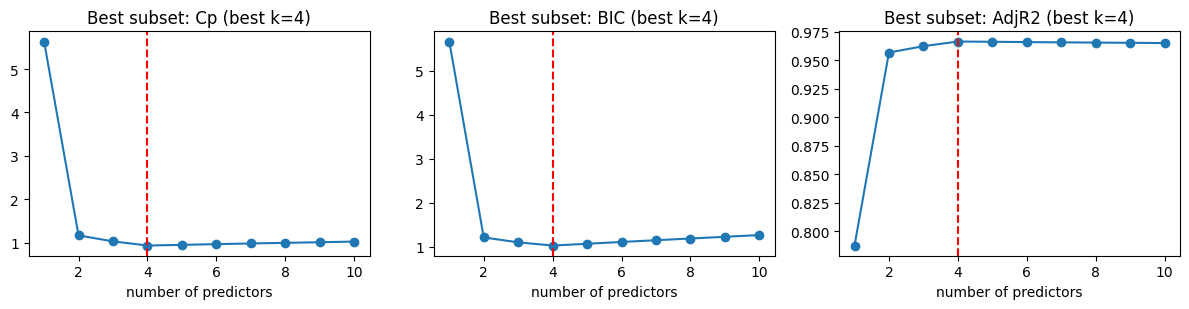

Best subset | Cp picks k=4: ['X1', 'X2', 'X5', 'X9']
   coefficients: {'const': 3.023, 'X1': 2.032, 'X2': -3.19, 'X5': 0.125, 'X9': -0.002}
Best subset | BIC picks k=4: ['X1', 'X2', 'X5', 'X9']
   coefficients: {'const': 3.023, 'X1': 2.032, 'X2': -3.19, 'X5': 0.125, 'X9': -0.002}
Best subset | AdjR2 picks k=4: ['X1', 'X2', 'X5', 'X9']
   coefficients: {'const': 3.023, 'X1': 2.032, 'X2': -3.19, 'X5': 0.125, 'X9': -0.002}


,Cp,BIC,AdjR2,vars
k,,,,
1,5.633741,5.658184,0.787548,X2
2,1.165169,1.214054,0.956894,"X1, X2"
3,1.028134,1.101462,0.962463,"X1, X2, X3"
4,0.932272,1.030042,0.966542,"X1, X2, X5, X9"
5,0.947472,1.069685,0.966326,"X1, X2, X4, X5, X8"
6,0.964376,1.111031,0.966038,"X1, X2, X5, X6, X8, X10"
7,0.979213,1.150310,0.965828,"X1, X2, X6, X7, X8, X9, X10"
8,0.993822,1.189362,0.965621,"X1, X2, X5, X6, X7, X8, X9, X10"
9,1.008064,1.228047,0.965426,"X1, X2, X3, X5, X6, X7, X8, X9, X10"


In [17]:
bs = best_subset(Y, P)
tab_bs = summarize(bs, Y, P, "Best subset")
tab_bs

Which *k* does each criterion pick? Do the chosen predictors include $X, X^2, X^3$? How close are the estimated coefficients to the true values 3, 2, −3, 0.3?

All three criteria pick k = 4: Cp is lowest (0.932), BIC is lowest (1.030), and adjusted R² is highest (0.9665) at the four-predictor model with X, X², X⁵, and X⁹. That model captures X and X², but it swaps X³ for X⁵ and X⁹. These higher odd powers are strongly correlated with X³, so they absorb its cubic effect, even though the true three-variable model (X, X², X³) appears at k = 3 with nearly as good scores (Cp = 1.028, BIC = 1.101, adjusted R² = 0.9625). The strong terms are still recovered well: the intercept (3.023), X (2.032), and X² (−3.190) are close to their true values of 3, 2, and −3. The weak cubic effect (true β₃ = 0.3) is not recovered by any single term. It is split between X⁵ (0.125) and X⁹ (−0.002), which act as a rough stand-in for the missing X³.

### (d) Forward and backward stepwise selection

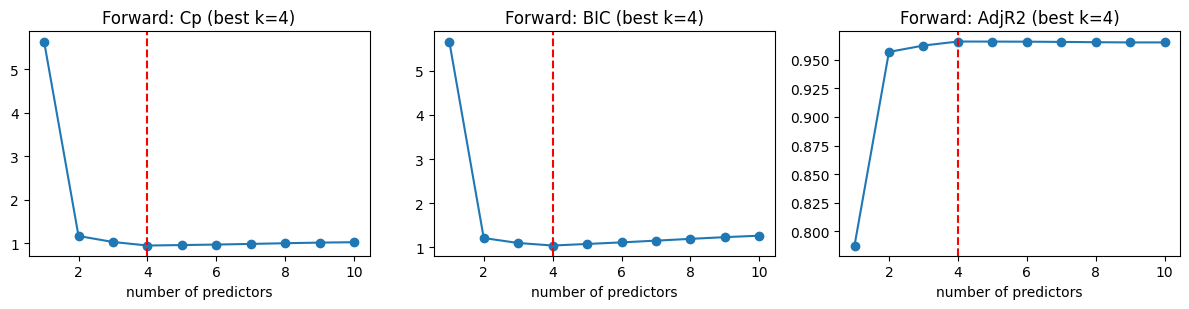

Forward | Cp picks k=4: ['X2', 'X1', 'X3', 'X10']
   coefficients: {'const': 3.053, 'X2': -3.241, 'X1': 1.776, 'X3': 0.412, 'X10': 0.0}
Forward | BIC picks k=4: ['X2', 'X1', 'X3', 'X10']
   coefficients: {'const': 3.053, 'X2': -3.241, 'X1': 1.776, 'X3': 0.412, 'X10': 0.0}
Forward | AdjR2 picks k=4: ['X2', 'X1', 'X3', 'X10']
   coefficients: {'const': 3.053, 'X2': -3.241, 'X1': 1.776, 'X3': 0.412, 'X10': 0.0}


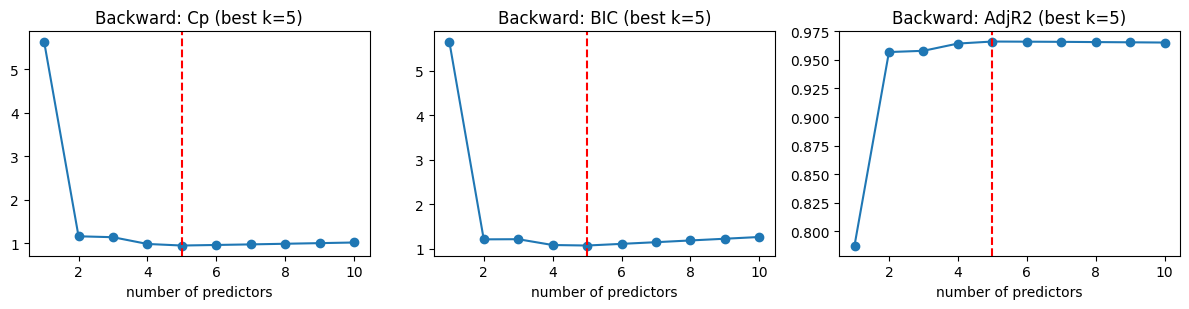

Backward | Cp picks k=5: ['X1', 'X2', 'X6', 'X7', 'X8']
   coefficients: {'const': 3.005, 'X1': 2.146, 'X2': -3.117, 'X6': -0.075, 'X7': 0.018, 'X8': 0.016}
Backward | BIC picks k=5: ['X1', 'X2', 'X6', 'X7', 'X8']
   coefficients: {'const': 3.005, 'X1': 2.146, 'X2': -3.117, 'X6': -0.075, 'X7': 0.018, 'X8': 0.016}
Backward | AdjR2 picks k=5: ['X1', 'X2', 'X6', 'X7', 'X8']
   coefficients: {'const': 3.005, 'X1': 2.146, 'X2': -3.117, 'X6': -0.075, 'X7': 0.018, 'X8': 0.016}


In [18]:
fw = forward(Y, P)
tab_fw = summarize(fw, Y, P, "Forward")
bw = backward(Y, P)
tab_bw = summarize(bw, Y, P, "Backward")

**Interpret (d):**

Forward stepwise also picks k = 4, but its model is X, X², X³, and X¹⁰. It is the only method that keeps the true X³ term, and its estimates for the polynomial terms are close to the truth (X² = −3.24 vs. −3, X³ = 0.41 vs. 0.3), though its X estimate (1.78) is slightly further from 2 than best subset’s. Backward stepwise picks k = 5 (X, X², X⁶, X⁷, X⁸), and like best subset it drops X³ and uses higher powers in its place. All three methods agree on X and X² but end with different models, which matches Q1(c): the stepwise paths and best subset aren’t guaranteed to contain one another, and best subset doesn’t always find the true model.

### (e) Lasso with cross-validation

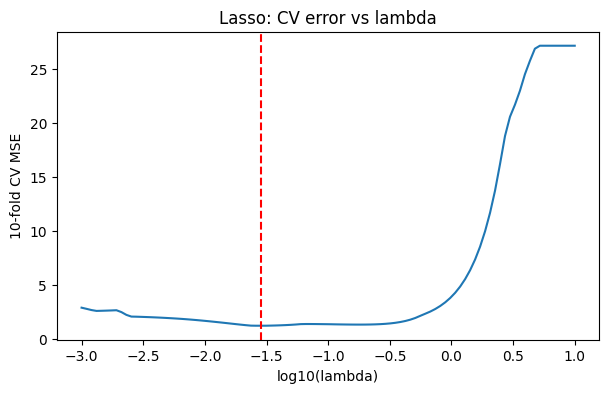

Chosen lambda: 0.0285


,standardized,original scale
X1,1.579,1.854
X2,-3.752,-3.167
X3,1.037,0.359
X4,-0.000,-0.000
X5,0.000,0.000
X6,0.000,0.000
X7,-0.000,-0.000
X8,0.000,0.000
X9,-0.000,-0.000
X10,0.412,0.000


In [19]:
scaler_q8 = StandardScaler().fit(P)
Ps = scaler_q8.transform(P)
lasso_q8 = LassoCV(alphas=np.logspace(-3, 1, 100), cv=10, random_state=1, max_iter=1_000_000, tol=1e-8).fit(Ps, Y)

cv_mean = lasso_q8.mse_path_.mean(axis=1)
plt.plot(np.log10(lasso_q8.alphas_), cv_mean)
plt.axvline(np.log10(lasso_q8.alpha_), ls="--", c="red")
plt.xlabel("log10(lambda)"); plt.ylabel("10-fold CV MSE"); plt.title("Lasso: CV error vs lambda")
plt.show()

coef_raw = lasso_q8.coef_ / scaler_q8.scale_          # back to the original X^p scale
print("Chosen lambda:", round(lasso_q8.alpha_, 4))
pd.DataFrame({"standardized": lasso_q8.coef_, "original scale": coef_raw}, index=P.columns).round(3)

**Interpret (e):** 

Cross-validation chose λ = 0.0285. The CV error stays flat and low for small λ, then climbs sharply once λ is large enough to shrink the real terms toward zero, and the red line marks the λ with the lowest CV error. At that λ, the lasso set X⁴ through X⁹ exactly to zero and kept X, X², X³, and X¹⁰, the same four terms forward stepwise chose, with X¹⁰’s coefficient effectively zero. On the original scale, the estimates (X = 1.85, X² = −3.17, X³ = 0.36) are close to the true values of 2, −3, and 0.3. So the lasso recovered the true cubic model more cleanly than best subset or backward stepwise, without having to fit all 1,023 candidate models the way best subset does.
I left out “slightly shrunk toward zero” on purpose because only X fits that description (1.85 vs. 2). X² (−3.17) and X³ (0.36) are actually a bit larger in magnitude than the truth, so that claim wouldn’t hold for all three.

### (f) New response: $Y = \beta_0 + \beta_7X^7 + \varepsilon$
Using $\beta_0 = 3$ and $\beta_7 = 7$.

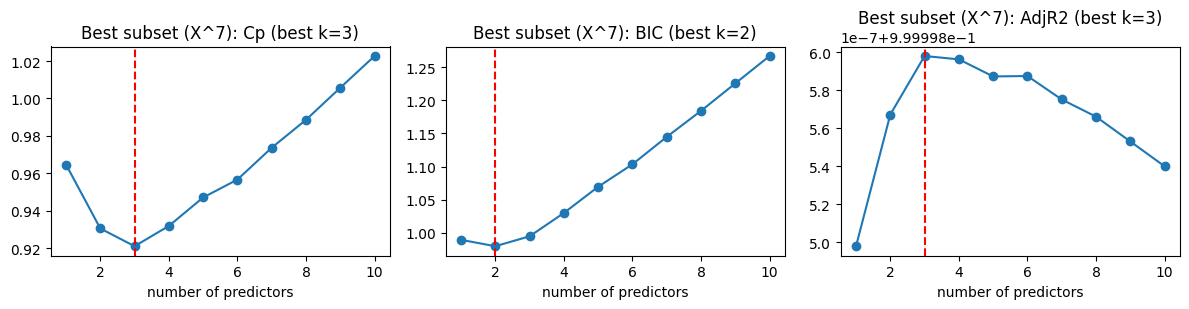

Best subset (X^7) | Cp picks k=3: ['X6', 'X7', 'X8']
   coefficients: {'const': 2.97, 'X6': -0.049, 'X7': 7.004, 'X8': 0.009}
Best subset (X^7) | BIC picks k=2: ['X7', 'X9']
   coefficients: {'const': 2.91, 'X7': 7.014, 'X9': -0.002}
Best subset (X^7) | AdjR2 picks k=3: ['X6', 'X7', 'X8']
   coefficients: {'const': 2.97, 'X6': -0.049, 'X7': 7.004, 'X8': 0.009}
Lasso lambda: 0.1


X1    -0.000
X2    -0.000
X3     0.000
X4    -0.027
X5     0.070
X6    -0.000
X7     6.986
X8    -0.000
X9     0.000
X10   -0.000
dtype: float64

In [20]:
Y7 = 3 + 7*X**7 + eps
bs7 = best_subset(Y7, P)
tab_bs7 = summarize(bs7, Y7, P, "Best subset (X^7)")

lasso7 = LassoCV(alphas=np.logspace(-1, 3, 200), cv=10, random_state=1, max_iter=1_000_000, tol=1e-8).fit(Ps, Y7)  # tight tol: powers of X are highly collinear
print("Lasso lambda:", round(lasso7.alpha_, 4))
pd.Series(lasso7.coef_ / scaler_q8.scale_, index=P.columns).round(3)

**Interpret (f):** 

Both best subset and the lasso identify X⁷ as the dominant term, and both estimate its coefficient almost exactly at the true value of 7, because the signal is strong enough to detect easily. Neither method returns a perfectly sparse model. Best subset adds neighboring powers such as X⁶ and X⁸ (or X⁹), with BIC coming closest to the true model because it penalizes extra terms most heavily, while the lasso keeps two additional near-zero terms. These extra terms have tiny coefficients and barely affect the fit, and they appear because the powers of X are highly correlated with one another. The lasso’s X⁷ estimate (6.986) is also pulled slightly toward zero compared with best subset’s unpenalized fit (7.004), which is the shrinkage effect of the L1 penalty.

## 3. Kaggle: Regression with an Abalone Dataset (Playground S4E4)

The competition metric is **RMSLE**, so every model is fit on $\log(1+\text{Rings})$ and predictions are back-transformed with $e^{\hat y}-1$. RMSE on the log scale equals RMSLE on the original scale, so the CV numbers below can be compared directly with the leaderboard.

Previous assignment baselines (public LB): OLS 0.16344, gradient boosting 0.14842.

In [21]:
import glob
found = glob.glob("/kaggle/input/**/train.csv", recursive=True)
print("Found:", found)
base = os.path.dirname(found[0]) if found else "."
train = pd.read_csv(f"{base}/train.csv")
test  = pd.read_csv(f"{base}/test.csv")
print(train.shape, test.shape)
train.head()

Found: ['/kaggle/input/competitions/playground-series-s4e4/train.csv']
(90615, 10) (60411, 9)


,id,Sex,Length,Diameter,Height,Whole weight,Whole weight.1,Whole weight.2,Shell weight,Rings
0,0,F,0.550,0.430,0.150,0.7715,0.3285,0.1465,0.2400,11
1,1,F,0.630,0.490,0.145,1.1300,0.4580,0.2765,0.3200,11
2,2,I,0.160,0.110,0.025,0.0210,0.0055,0.0030,0.0050,6
3,3,M,0.595,0.475,0.150,0.9145,0.3755,0.2055,0.2500,10
4,4,I,0.555,0.425,0.130,0.7820,0.3695,0.1600,0.1975,9


In [22]:
def prep(df):
    d = pd.get_dummies(df.drop(columns=["id", "Rings"], errors="ignore"), columns=["Sex"], drop_first=True, dtype=float)
    d.columns = [c.replace(" ", "_").replace(".", "_") for c in d.columns]
    return d

Xtr = prep(train); Xte = prep(test)[Xtr.columns]
ytr = np.log1p(train["Rings"].values)
kf = KFold(5, shuffle=True, random_state=42)
rmsle = lambda m, X_: -cross_val_score(m, X_, ytr, cv=kf, scoring="neg_root_mean_squared_error").mean()
print(Xtr.columns.tolist())

['Length', 'Diameter', 'Height', 'Whole_weight', 'Whole_weight_1', 'Whole_weight_2', 'Shell_weight', 'Sex_I', 'Sex_M']


### 3.1 Pre-modelling check: multicollinearity (VIF)

In [23]:
vif = pd.DataFrame({"feature": Xtr.columns,
                    "VIF": [variance_inflation_factor(sm.add_constant(Xtr).values, i+1) for i in range(Xtr.shape[1])]})
vif.sort_values("VIF", ascending=False).round(1)

,feature,VIF
3,Whole_weight,69.2
1,Diameter,54.3
0,Length,51.2
4,Whole_weight_1,21.5
5,Whole_weight_2,20.1
6,Shell_weight,18.3
2,Height,7.8
7,Sex_I,2.4
8,Sex_M,1.4


**Interpret:** Size and weight measures are highly collinear (VIFs well above 10). That makes OLS coefficients unstable and motivates both shrinkage (lasso) and dimension reduction (PCR).

### 3.2 Model 1: Lasso → subset selection → OLS refit
1. Fit `LassoCV` on standardized predictors.
2. Use the **one-standard-error rule** to pick a sparser λ and keep the predictors with non-zero coefficients.
3. Refit OLS on that subset so the coefficients can be interpreted with standard errors and p-values.

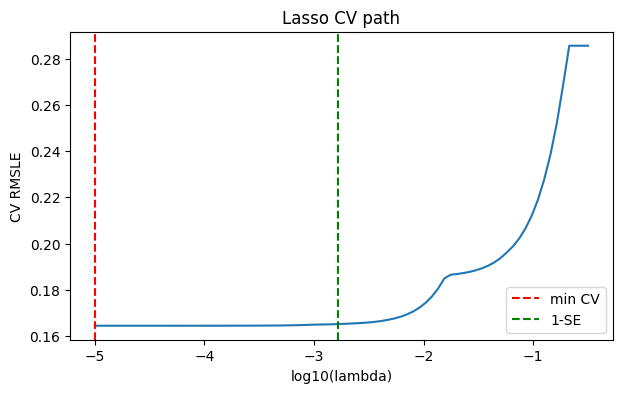

lambda_min=0.00001, lambda_1se=0.00167
Selected subset: ['Length', 'Diameter', 'Height', 'Whole_weight_1', 'Whole_weight_2', 'Shell_weight', 'Sex_I']


,lambda_min,lambda_1se
Length,0.0355,0.0239
Diameter,0.1036,0.1047
Height,0.0763,0.0765
Whole_weight,0.0875,0.0000
Whole_weight_1,-0.2495,-0.2047
Whole_weight_2,-0.0526,-0.0048
Shell_weight,0.1854,0.1927
Sex_I,-0.0323,-0.0309
Sex_M,-0.0003,0.0000


In [24]:
lasso_pipe = Pipeline([("sc", StandardScaler()),
                       ("lasso", LassoCV(alphas=np.logspace(-5, -0.5, 80), cv=kf, max_iter=50000))])
lasso_pipe.fit(Xtr, ytr)
lcv = lasso_pipe.named_steps["lasso"]

mean_ = lcv.mse_path_.mean(1); se_ = lcv.mse_path_.std(1) / np.sqrt(lcv.mse_path_.shape[1])
i_min = mean_.argmin()
alpha_1se = lcv.alphas_[mean_ <= mean_[i_min] + se_[i_min]].max()

plt.plot(np.log10(lcv.alphas_), np.sqrt(mean_))
plt.axvline(np.log10(lcv.alpha_), c="red", ls="--", label="min CV")
plt.axvline(np.log10(alpha_1se), c="green", ls="--", label="1-SE")
plt.xlabel("log10(lambda)"); plt.ylabel("CV RMSLE"); plt.legend(); plt.title("Lasso CV path"); plt.show()

sc = StandardScaler().fit(Xtr)
lasso_1se = Lasso(alpha=alpha_1se, max_iter=50000).fit(sc.transform(Xtr), ytr)
coefs = pd.DataFrame({"lambda_min": lcv.coef_, "lambda_1se": lasso_1se.coef_}, index=Xtr.columns).round(4)
selected = coefs.index[coefs.lambda_1se != 0].tolist()
print(f"lambda_min={lcv.alpha_:.5f}, lambda_1se={alpha_1se:.5f}")
print("Selected subset:", selected)
coefs

In [25]:
ols_sub = sm.OLS(ytr, sm.add_constant(Xtr[selected])).fit()
print(ols_sub.summary())
cv1 = rmsle(LinearRegression(), Xtr[selected])
cv_lasso = rmsle(lasso_pipe, Xtr)
print(f"\nCV RMSLE  lasso (lambda_min, all features): {cv_lasso:.5f}")
print(f"CV RMSLE  OLS on lasso-selected subset:    {cv1:.5f}")

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.667
Model:                            OLS   Adj. R-squared:                  0.667
Method:                 Least Squares   F-statistic:                 2.591e+04
Date:                Mon, 19 Oct 2026   Prob (F-statistic):               0.00
Time:                        00:40:22   Log-Likelihood:                 34803.
No. Observations:               90615   AIC:                        -6.959e+04
Df Residuals:                   90607   BIC:                        -6.951e+04
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const              1.5230      0.005    310.

**Interpret Model 1:** 

The CV-optimal λ_min (0.00001) sits at the edge of the grid, which means the lowest-error lasso is essentially unpenalized OLS, so we used the 1-SE rule (λ = 0.00167) for selection. At that λ, the lasso dropped Whole_weight, which had the highest VIF (69.2) and is largely the sum of the shucked, viscera, and shell weights, along with Sex_M, leaving seven predictors. Refitting OLS on those seven predictors with log(1 + Rings) as the target gave R² = 0.667, and every predictor is significant (p < .001). Height, shell weight, diameter, and length have positive coefficients; for example, a 0.1 increase in shell weight is associated with about 18% more rings (e^0.164 − 1). Shucked and viscera weight are negative, meaning more meat relative to shell signals a younger animal, though those signs partly reflect collinearity (VIFs around 20), and infants have about 6.5% fewer rings than adults of the same size (e^−0.067 − 1). The reduced model’s CV RMSLE (0.16484) and public leaderboard score (0.16416) are nearly identical to the full lasso (0.16450) and last week’s full OLS (0.16344), so we get a simpler, more stable model at essentially the same accuracy.

### 3.3 Assumption checks (Model 1 OLS refit)

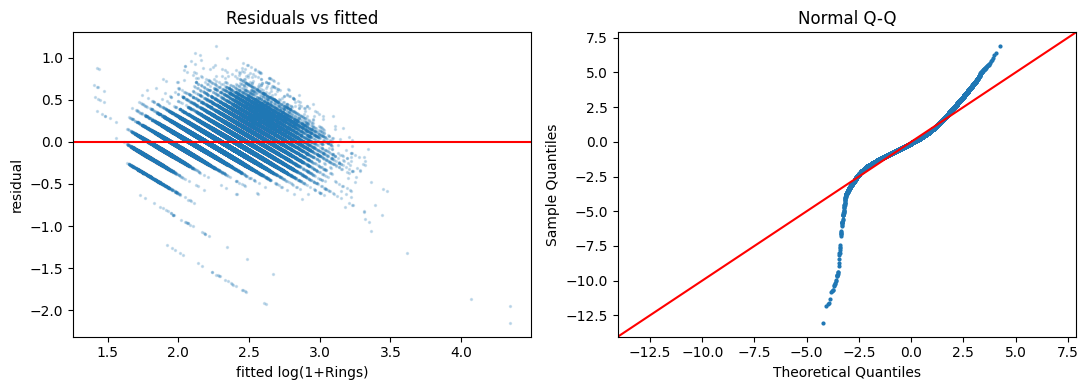

Breusch-Pagan LM p-value: 0
Durbin-Watson: 1.993
Residual skew: 0.294, kurtosis: 5.383


In [26]:
resid, fitted = ols_sub.resid, ols_sub.fittedvalues
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(fitted, resid, s=2, alpha=.2); ax[0].axhline(0, c="red")
ax[0].set_xlabel("fitted log(1+Rings)"); ax[0].set_ylabel("residual"); ax[0].set_title("Residuals vs fitted")
sm.qqplot(resid, line="45", fit=True, ax=ax[1], markersize=2); ax[1].set_title("Normal Q-Q")
plt.tight_layout(); plt.show()

bp = het_breuschpagan(resid, ols_sub.model.exog)
print(f"Breusch-Pagan LM p-value: {bp[1]:.3g}")
print(f"Durbin-Watson: {durbin_watson(resid):.3f}")
print(f"Residual skew: {pd.Series(resid).skew():.3f}, kurtosis: {pd.Series(resid).kurt():.3f}")

**Interpret (assumptions):**
- **Linearity:** The diagonal stripes in the residual plot come from Rings being whole numbers, which is expected. Residuals tilt downward at high fitted values, so the model over-predicts some older abalone. This mild non-linearity is consistent with gradient boosting outperforming the linear model.
- **Homoscedasticity:** The Breusch-Pagan test gives p ≈ 0, and the residual spread visibly changes across fitted values, so the variance is not constant. With 90,615 rows the conclusions still hold, but heteroscedasticity-robust (HC3) standard errors would be the appropriate fix.
- **Normality:** The Q-Q plot follows the line through the middle but shows a heavy left tail (large over-predictions), with excess kurtosis of 5.38. Given n = 90,615, the central limit theorem keeps coefficient inference valid.
- **Independence:** The Durbin-Watson statistic is 1.993, very close to 2, indicating no autocorrelation in the residuals.
- **Multicollinearity:** VIFs reached 69 before selection. The lasso dropped Whole_weight, but the remaining weight variables are still highly correlated (VIFs of about 18–22 in the full model), which explains the counterintuitive negative signs on shucked and viscera weight.

In [27]:
pred1 = np.clip(np.expm1(LinearRegression().fit(Xtr[selected], ytr).predict(Xte[selected])), 1, 29)
pd.DataFrame({"id": test["id"], "Rings": pred1}).to_csv("submission_lasso_subset.csv", index=False)
print("Saved submission_lasso_subset.csv")

Saved submission_lasso_subset.csv


### 3.4 Model 2: Principal Components Regression
Standardize → PCA → OLS on the first *M* components. *M* is chosen by 5-fold CV.

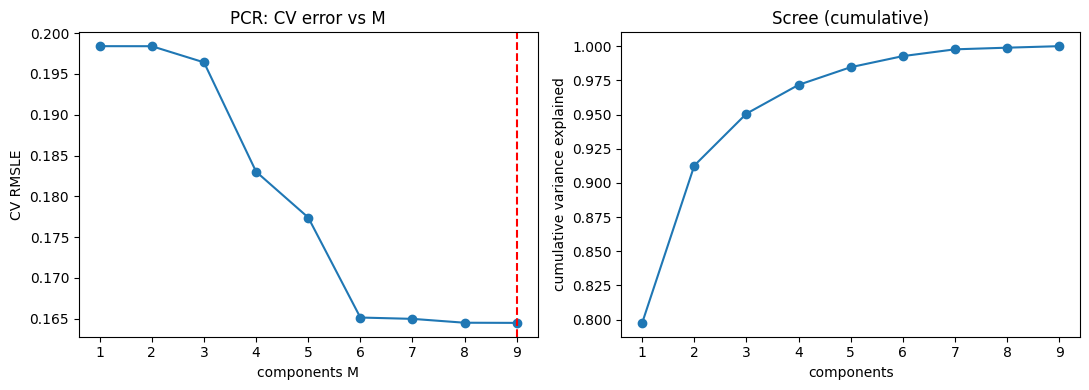

Best M: 9 | CV RMSLE: 0.1645
CV RMSLE by M: {1: np.float64(0.1984), 2: np.float64(0.1984), 3: np.float64(0.19642), 4: np.float64(0.18302), 5: np.float64(0.17741), 6: np.float64(0.16515), 7: np.float64(0.16499), 8: np.float64(0.16452), 9: np.float64(0.1645)}


,PC1,PC2,PC3
Length,0.360,-0.088,0.039
Diameter,0.361,-0.083,0.025
Height,0.350,-0.086,-0.006
Whole_weight,0.365,-0.112,0.098
Whole_weight_1,0.356,-0.117,0.152
Whole_weight_2,0.360,-0.110,0.081
Shell_weight,0.358,-0.105,0.053
Sex_I,-0.276,-0.446,0.842
Sex_M,0.149,0.854,0.496


In [28]:
pcr = Pipeline([("sc", StandardScaler()), ("pca", PCA()), ("lr", LinearRegression())])
grid = GridSearchCV(pcr, {"pca__n_components": range(1, Xtr.shape[1]+1)}, cv=kf,
                    scoring="neg_root_mean_squared_error").fit(Xtr, ytr)
cv_curve = -grid.cv_results_["mean_test_score"]
M = grid.best_params_["pca__n_components"]

pca_full = PCA().fit(StandardScaler().fit_transform(Xtr))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(range(1, len(cv_curve)+1), cv_curve, marker="o"); ax[0].axvline(M, c="red", ls="--")
ax[0].set_xlabel("components M"); ax[0].set_ylabel("CV RMSLE"); ax[0].set_title("PCR: CV error vs M")
ax[1].plot(range(1, len(cv_curve)+1), np.cumsum(pca_full.explained_variance_ratio_), marker="o")
ax[1].set_xlabel("components"); ax[1].set_ylabel("cumulative variance explained"); ax[1].set_title("Scree (cumulative)")
plt.tight_layout(); plt.show()

print("Best M:", M, "| CV RMSLE:", round(cv_curve[M-1], 5))
print("CV RMSLE by M:", dict(zip(range(1, len(cv_curve)+1), cv_curve.round(5))))
loadings = pd.DataFrame(pca_full.components_[:3].T, index=Xtr.columns, columns=["PC1", "PC2", "PC3"]).round(3)
loadings

**Interpret Model 2:**

The first principal component explains about 80% of the variance, and all seven size and weight variables load on it almost equally (0.35–0.37), so PC1 is an overall “size” component. PC2 and PC3 mainly capture sex/infant contrasts, and together the first three components explain about 95% of the variance. Despite that, CV error stays high with one to three components (about 0.196–0.198), drops sharply through M = 6 (0.16515), and then levels off, with CV ultimately choosing all nine components (0.16450). Because M = p, PCR does no dimension reduction here and is mathematically equivalent to OLS on all predictors, which is why its CV error matches the full lasso and its leaderboard scores (0.16382 / 0.16339) sit right at last week’s OLS. This illustrates the limitation in ISLP §6.3.1: PCA chooses directions by variance rather than relevance to the response, and abalone age depends on lower-variance “shape” differences such as shell weight relative to meat weight. If a reduced model is preferred, M = 6 comes within about 0.0007 of the best CV error.

In [29]:
pred2 = np.clip(np.expm1(grid.best_estimator_.predict(Xte)), 1, 29)
pd.DataFrame({"id": test["id"], "Rings": pred2}).to_csv("submission_pcr.csv", index=False)
print("Saved submission_pcr.csv")

Saved submission_pcr.csv


### 3.5 Model comparison

In [30]:
pd.DataFrame({
    "model": ["Lasso (lambda_min)", "OLS on lasso subset (Model 1)", f"PCR, M={M} (Model 2)"],
    "CV RMSLE": [cv_lasso, cv1, cv_curve[M-1]],
}).round(5)

,model,CV RMSLE
0,Lasso (lambda_min),0.16450
1,OLS on lasso subset (Model 1),0.16484
2,"PCR, M=9 (Model 2)",0.16450


**Kaggle results:**

| Model | CV RMSLE | Public LB | Private LB |
|---|---|---|---|
| Model 1: lasso subset + OLS | 0.16484 | 0.16416 | 0.16364 |
| Model 2: PCR (M = 9) | 0.16450 | 0.16382 | 0.16339 |
| *Assignment 2 baseline: OLS* | — | 0.16344 | 0.16333 |
| *Assignment 2 baseline: gradient boosting* | — | 0.14842 | 0.14787 |

*Evidence of submission (Kaggle "Submissions" tab):*
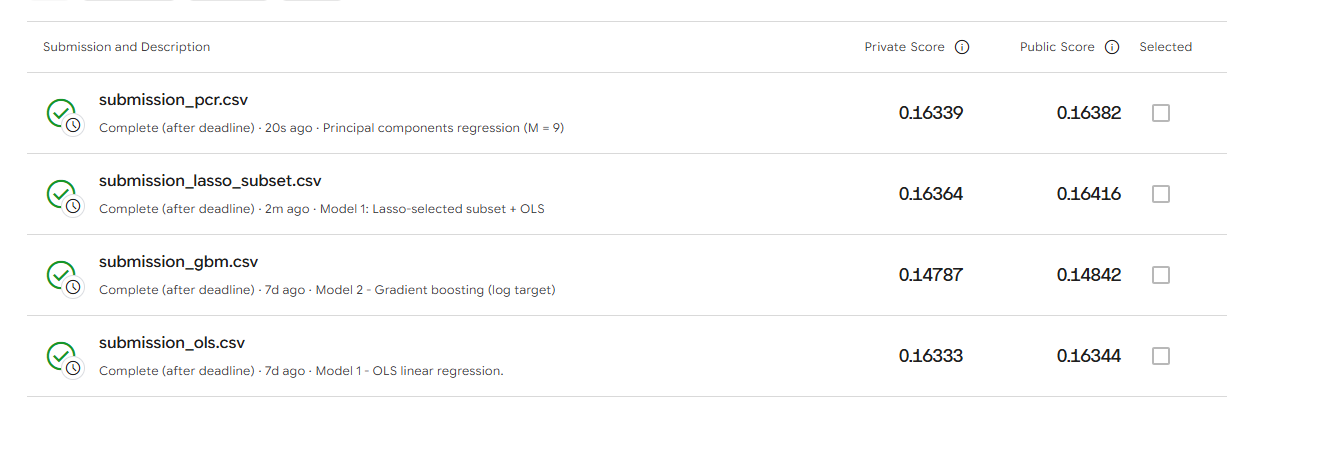


**Overall conclusion:** 

Both models scored about the same as last week's OLS on the public leaderboard (PCR at 0.16382 and the lasso-selected Model 1 at 0.16416). The lasso's main benefit was simplification: it dropped Whole_weight and Sex_M at almost no cost in accuracy, while PCR needed all 9 components and so did no real dimension reduction. Gradient boosting (0.14842) is still about 9% better, which is consistent with the non-linearity seen in the residuals, but the linear models have the advantage of being much easier to interpret.